# Phishing Email Detection — Combined Dataset Training
### CN6000 Final Year Project — BSc Computer Science

This notebook trains and evaluates SVM and Logistic Regression on a **combined dataset**
merging CEAS_08 (2008 benchmark) with a modern Kaggle phishing dataset (2023).

**Pipeline:**
1. Load and inspect both datasets
2. Standardise labels and columns
3. Merge and deduplicate
4. TF-IDF feature extraction
5. 80/20 train/test split
6. Train SVM and Logistic Regression
7. Evaluate both models
8. Compare before vs after results
9. Save best model

## Step 1 — Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report, confusion_matrix
)

print('All libraries imported successfully.')

All libraries imported successfully.


## Step 2 — Upload Both Datasets

When the upload box appears, select **both files at once**:
- `CEAS_08.csv`
- `Phishing_Email.csv`

In [ ]:
from google.colab import files
uploaded = files.upload()
print('Files uploaded:', list(uploaded.keys()))

Saving CEAS_08.csv to CEAS_08.csv
Saving Phishing_Email.csv to Phishing_Email.csv
Files uploaded: ['CEAS_08.csv', 'Phishing_Email.csv']


## Step 3 — Load and Inspect Both Datasets

In [ ]:
# Load CEAS_08
ceas = pd.read_csv('CEAS_08.csv')
print('CEAS_08 loaded:')
print(f'  Rows:    {len(ceas):,}')
print(f'  Columns: {ceas.columns.tolist()}')
print(f'  Labels:  {ceas["label"].value_counts().to_dict()}')
print()

CEAS_08 loaded:
  Rows:    39,154
  Columns: ['sender', 'receiver', 'date', 'subject', 'body', 'label', 'urls']
  Labels:  {1: 21842, 0: 17312}



In [ ]:
# Load Kaggle dataset
kaggle = pd.read_csv('Phishing_Email.csv')
print('Kaggle Phishing Email dataset loaded:')
print(f'  Rows:    {len(kaggle):,}')
print(f'  Columns: {kaggle.columns.tolist()}')
print(f'  Labels:  {kaggle["Email Type"].value_counts().to_dict()}')

Kaggle Phishing Email dataset loaded:
  Rows:    18,650
  Columns: ['Unnamed: 0', 'Email Text', 'Email Type']
  Labels:  {'Safe Email': 11322, 'Phishing Email': 7328}


## Step 4 — Standardise Both Datasets

We normalise both datasets to the same two columns:
- `text` — the email content
- `label` — 1 for phishing, 0 for legitimate

In [ ]:
# ── Standardise CEAS_08 ──
ceas['subject'] = ceas['subject'].fillna('')
ceas['body']    = ceas['body'].fillna('')
ceas_std = pd.DataFrame({
    'text':   ceas['subject'] + ' ' + ceas['body'],
    'label':  ceas['label'],
    'source': 'CEAS_08'
})

print(f'CEAS_08 standardised: {len(ceas_std):,} rows')
print(f'  Phishing:   {(ceas_std["label"]==1).sum():,}')
print(f'  Legitimate: {(ceas_std["label"]==0).sum():,}')

CEAS_08 standardised: 39,154 rows
  Phishing:   21,842
  Legitimate: 17,312


In [ ]:
# ── Standardise Kaggle dataset ──
# Drop nulls
kaggle = kaggle.dropna(subset=['Email Text'])

# Convert labels: 'Phishing Email' → 1, 'Safe Email' → 0
kaggle_std = pd.DataFrame({
    'text':   kaggle['Email Text'],
    'label':  kaggle['Email Type'].map({'Phishing Email': 1, 'Safe Email': 0}),
    'source': 'Kaggle'
})

print(f'Kaggle dataset standardised: {len(kaggle_std):,} rows')
print(f'  Phishing:   {(kaggle_std["label"]==1).sum():,}')
print(f'  Legitimate: {(kaggle_std["label"]==0).sum():,}')

Kaggle dataset standardised: 18,634 rows
  Phishing:   7,312
  Legitimate: 11,322


## Step 5 — Merge and Deduplicate

In [ ]:
# Combine both datasets
combined = pd.concat([ceas_std, kaggle_std], ignore_index=True)
print(f'Combined before deduplication: {len(combined):,} rows')

# Clean whitespace in text
combined['text'] = combined['text'].str.replace(r'\s+', ' ', regex=True).str.strip()

# Remove duplicate emails (same text regardless of source)
before = len(combined)
combined = combined.drop_duplicates(subset=['text'])
after = len(combined)
removed = before - after

print(f'Duplicates removed: {removed:,}')
print(f'Combined after deduplication: {len(combined):,} rows')
print()
print('Final label distribution:')
print(f'  Phishing:   {(combined["label"]==1).sum():,} ({(combined["label"]==1).sum()/len(combined)*100:.1f}%)')
print(f'  Legitimate: {(combined["label"]==0).sum():,} ({(combined["label"]==0).sum()/len(combined)*100:.1f}%)')
print()
print('Source breakdown:')
print(combined['source'].value_counts())

Combined before deduplication: 57,788 rows
Duplicates removed: 1,310
Combined after deduplication: 56,478 rows

Final label distribution:
  Phishing:   28,212 (50.0%)
  Legitimate: 28,266 (50.0%)

Source breakdown:
source
CEAS_08    38963
Kaggle     17515
Name: count, dtype: int64


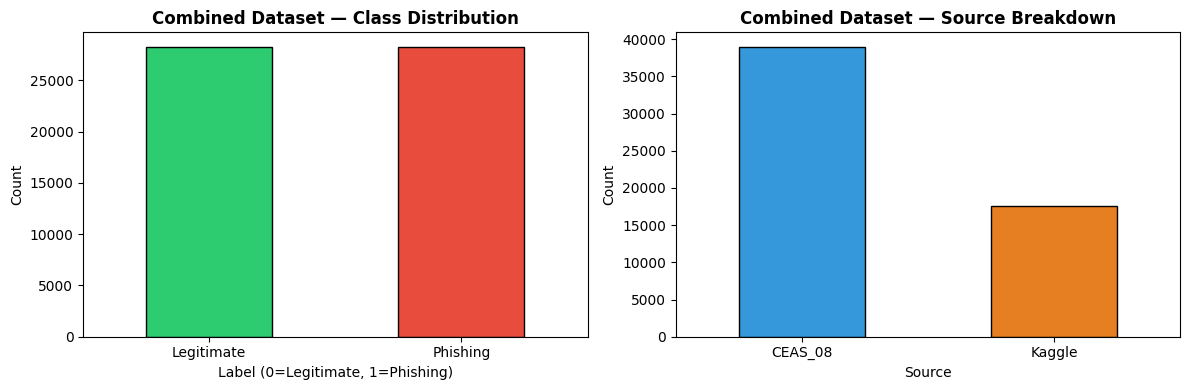

Saved as combined_dataset_distribution.png


In [ ]:
# Visualise combined dataset distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Class distribution
combined['label'].value_counts().plot(
    kind='bar', ax=axes[0],
    color=['#2ecc71', '#e74c3c'],
    edgecolor='black'
)
axes[0].set_title('Combined Dataset — Class Distribution', fontweight='bold')
axes[0].set_xlabel('Label (0=Legitimate, 1=Phishing)')
axes[0].set_ylabel('Count')
axes[0].set_xticklabels(['Legitimate', 'Phishing'], rotation=0)

# Source breakdown
combined['source'].value_counts().plot(
    kind='bar', ax=axes[1],
    color=['#3498db', '#e67e22'],
    edgecolor='black'
)
axes[1].set_title('Combined Dataset — Source Breakdown', fontweight='bold')
axes[1].set_xlabel('Source')
axes[1].set_ylabel('Count')
axes[1].set_xticklabels(['CEAS_08', 'Kaggle'], rotation=0)

plt.tight_layout()
plt.savefig('combined_dataset_distribution.png', dpi=150)
plt.show()
print('Saved as combined_dataset_distribution.png')

## Step 6 — Train/Test Split

In [ ]:
X = combined['text']
y = combined['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f'Training set: {len(X_train):,} emails')
print(f'Test set:     {len(X_test):,} emails')
print()
print('Training set label distribution:')
print(y_train.value_counts())
print()
print('Test set label distribution:')
print(y_test.value_counts())

Training set: 45,182 emails
Test set:     11,296 emails

Training set label distribution:
label
0    22613
1    22569
Name: count, dtype: int64

Test set label distribution:
label
0    5653
1    5643
Name: count, dtype: int64


## Step 7 — TF-IDF Feature Extraction

In [ ]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    stop_words='english'
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(f'TF-IDF matrix shape (training): {X_train_tfidf.shape}')
print(f'TF-IDF matrix shape (test):     {X_test_tfidf.shape}')

TF-IDF matrix shape (training): (45182, 10000)
TF-IDF matrix shape (test):     (11296, 10000)


## Step 8 — Train and Evaluate SVM

In [ ]:
print('Training SVM...')
svm_model = LinearSVC(random_state=42, max_iter=1000)
svm_model.fit(X_train_tfidf, y_train)
svm_predictions = svm_model.predict(X_test_tfidf)

svm_accuracy  = accuracy_score(y_test, svm_predictions)
svm_precision = precision_score(y_test, svm_predictions)
svm_recall    = recall_score(y_test, svm_predictions)
svm_f1        = f1_score(y_test, svm_predictions)

print()
print('=' * 40)
print('        SVM RESULTS (COMBINED)')
print('=' * 40)
print(f'Accuracy:  {svm_accuracy:.4f}  ({svm_accuracy*100:.2f}%)')
print(f'Precision: {svm_precision:.4f}  ({svm_precision*100:.2f}%)')
print(f'Recall:    {svm_recall:.4f}  ({svm_recall*100:.2f}%)')
print(f'F1-Score:  {svm_f1:.4f}  ({svm_f1*100:.2f}%)')
print('=' * 40)
print()
print(classification_report(y_test, svm_predictions,
      target_names=['Legitimate (0)', 'Phishing (1)']))

Training SVM...

        SVM RESULTS (COMBINED)
Accuracy:  0.9902  (99.02%)
Precision: 0.9896  (98.96%)
Recall:    0.9908  (99.08%)
F1-Score:  0.9902  (99.02%)

                precision    recall  f1-score   support

Legitimate (0)       0.99      0.99      0.99      5653
  Phishing (1)       0.99      0.99      0.99      5643

      accuracy                           0.99     11296
     macro avg       0.99      0.99      0.99     11296
  weighted avg       0.99      0.99      0.99     11296



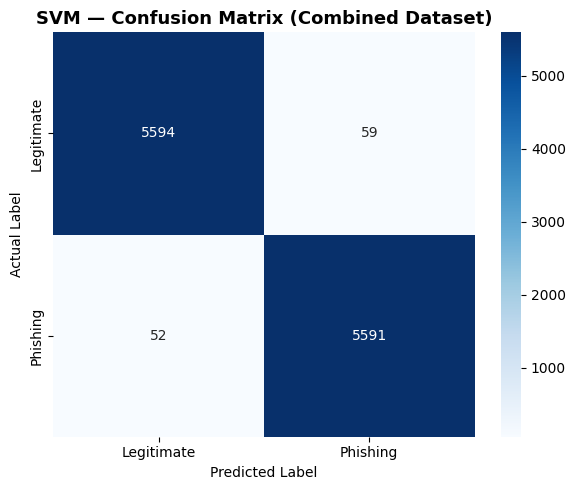

In [ ]:
# SVM Confusion Matrix
svm_cm = confusion_matrix(y_test, svm_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    svm_cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Legitimate', 'Phishing'],
    yticklabels=['Legitimate', 'Phishing']
)
plt.title('SVM — Confusion Matrix (Combined Dataset)', fontsize=13, fontweight='bold')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('svm_confusion_matrix_combined.png', dpi=150)
plt.show()

## Step 9 — Train and Evaluate Logistic Regression

In [ ]:
print('Training Logistic Regression...')
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)
lr_predictions = lr_model.predict(X_test_tfidf)

lr_accuracy  = accuracy_score(y_test, lr_predictions)
lr_precision = precision_score(y_test, lr_predictions)
lr_recall    = recall_score(y_test, lr_predictions)
lr_f1        = f1_score(y_test, lr_predictions)

print()
print('=' * 40)
print('  LOGISTIC REGRESSION (COMBINED)')
print('=' * 40)
print(f'Accuracy:  {lr_accuracy:.4f}  ({lr_accuracy*100:.2f}%)')
print(f'Precision: {lr_precision:.4f}  ({lr_precision*100:.2f}%)')
print(f'Recall:    {lr_recall:.4f}  ({lr_recall*100:.2f}%)')
print(f'F1-Score:  {lr_f1:.4f}  ({lr_f1*100:.2f}%)')
print('=' * 40)
print()
print(classification_report(y_test, lr_predictions,
      target_names=['Legitimate (0)', 'Phishing (1)']))

Training Logistic Regression...

  LOGISTIC REGRESSION (COMBINED)
Accuracy:  0.9872  (98.72%)
Precision: 0.9865  (98.65%)
Recall:    0.9878  (98.78%)
F1-Score:  0.9872  (98.72%)

                precision    recall  f1-score   support

Legitimate (0)       0.99      0.99      0.99      5653
  Phishing (1)       0.99      0.99      0.99      5643

      accuracy                           0.99     11296
     macro avg       0.99      0.99      0.99     11296
  weighted avg       0.99      0.99      0.99     11296



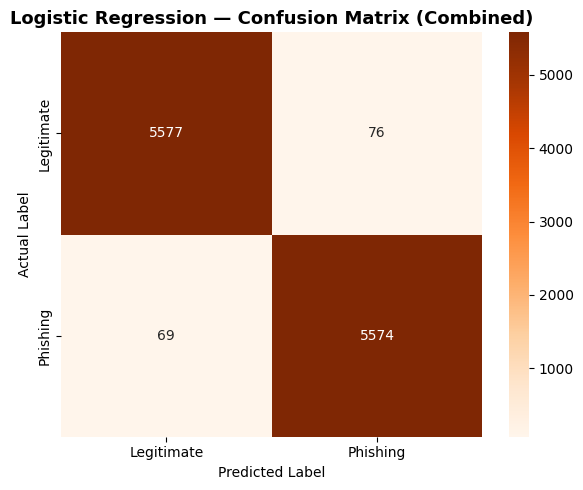

In [ ]:
# LR Confusion Matrix
lr_cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    lr_cm, annot=True, fmt='d', cmap='Oranges',
    xticklabels=['Legitimate', 'Phishing'],
    yticklabels=['Legitimate', 'Phishing']
)
plt.title('Logistic Regression — Confusion Matrix (Combined)', fontsize=13, fontweight='bold')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.savefig('lr_confusion_matrix_combined.png', dpi=150)
plt.show()

## Step 10 — Model Comparison (Combined Dataset)

In [ ]:
results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'SVM': [round(svm_accuracy,4), round(svm_precision,4),
            round(svm_recall,4),   round(svm_f1,4)],
    'Logistic Regression': [round(lr_accuracy,4), round(lr_precision,4),
                             round(lr_recall,4),   round(lr_f1,4)]
})
results['Winner'] = results.apply(
    lambda row: 'SVM' if row['SVM'] > row['Logistic Regression']
    else ('Logistic Regression' if row['Logistic Regression'] > row['SVM'] else 'Tie'),
    axis=1
)

print('=' * 60)
print('     MODEL COMPARISON — COMBINED DATASET')
print('=' * 60)
print(results.to_string(index=False))
print('=' * 60)

     MODEL COMPARISON — COMBINED DATASET
   Metric    SVM  Logistic Regression Winner
 Accuracy 0.9902               0.9872    SVM
Precision 0.9896               0.9865    SVM
   Recall 0.9908               0.9878    SVM
 F1-Score 0.9902               0.9872    SVM


## Step 11 — Before vs After Comparison

These are the CEAS_08-only results from the original notebook.
We compare them against the combined dataset results.

In [ ]:
# CEAS_08 only results (from original training notebook)
ceas_only = {
    'Accuracy':  0.9971,
    'Precision': 0.9970,
    'Recall':    0.9977,
    'F1-Score':  0.9974
}

# Combined dataset results
combined_results = {
    'Accuracy':  round(svm_accuracy, 4),
    'Precision': round(svm_precision, 4),
    'Recall':    round(svm_recall, 4),
    'F1-Score':  round(svm_f1, 4)
}

print('=' * 60)
print('     SVM — BEFORE vs AFTER COMPARISON')
print('=' * 60)
print(f'{"Metric":<15} {"CEAS_08 Only":>14} {"Combined":>12} {"Change":>10}')
print('-' * 60)
for metric in ['Accuracy', 'Precision', 'Recall', 'F1-Score']:
    before = ceas_only[metric]
    after  = combined_results[metric]
    change = after - before
    arrow  = '▲' if change > 0 else ('▼' if change < 0 else '=')
    print(f'{metric:<15} {before:>14.4f} {after:>12.4f} {arrow} {abs(change):.4f}')
print('=' * 60)

     SVM — BEFORE vs AFTER COMPARISON
Metric            CEAS_08 Only     Combined     Change
------------------------------------------------------------
Accuracy                0.9971       0.9902 ▼ 0.0069
Precision               0.9970       0.9896 ▼ 0.0074
Recall                  0.9977       0.9908 ▼ 0.0069
F1-Score                0.9974       0.9902 ▼ 0.0072


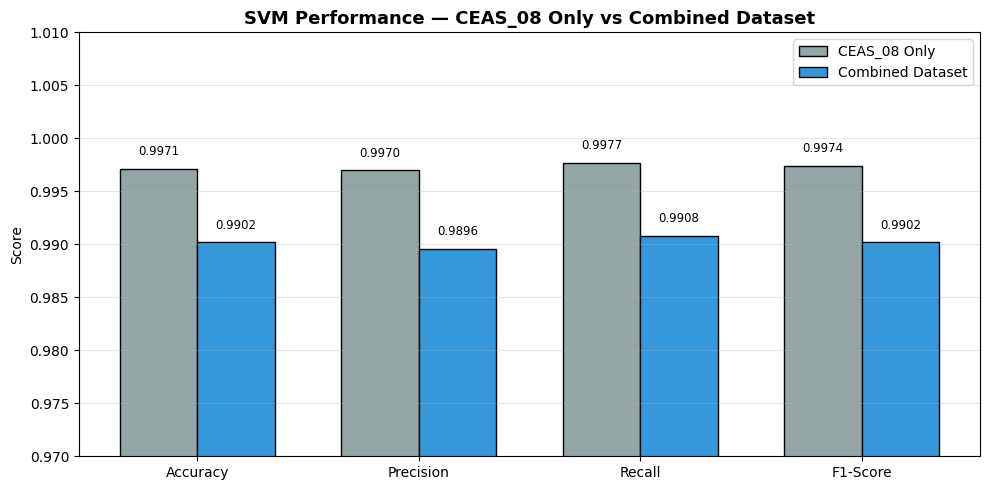

Saved as before_vs_after.png


In [ ]:
# Before vs After bar chart
metrics   = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
before_scores = [ceas_only[m]        for m in metrics]
after_scores  = [combined_results[m] for m in metrics]

x     = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, before_scores, width,
               label='CEAS_08 Only', color='#95a5a6', edgecolor='black')
bars2 = ax.bar(x + width/2, after_scores,  width,
               label='Combined Dataset', color='#3498db', edgecolor='black')

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=8.5)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=8.5)

ax.set_ylabel('Score')
ax.set_title('SVM Performance — CEAS_08 Only vs Combined Dataset',
             fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0.97, 1.01)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('before_vs_after.png', dpi=150)
plt.show()
print('Saved as before_vs_after.png')

## Step 12 — Save Updated Model

In [ ]:
joblib.dump(svm_model, 'svm_model.pkl')
joblib.dump(tfidf,     'tfidf_vectorizer.pkl')

print('Updated model saved:')
print('  svm_model.pkl        — trained on combined dataset')
print('  tfidf_vectorizer.pkl — fitted on combined dataset')
print()
print('Download and replace your existing model files.')

files.download('svm_model.pkl')
files.download('tfidf_vectorizer.pkl')

Updated model saved:
  svm_model.pkl        — trained on combined dataset
  tfidf_vectorizer.pkl — fitted on combined dataset

Download and replace your existing model files.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Final Summary

In [ ]:
tn,  fp,  fn,  tp  = svm_cm.ravel()
tn2, fp2, fn2, tp2 = lr_cm.ravel()

print('=' * 60)
print('         DISSERTATION RESULTS SUMMARY')
print('         COMBINED DATASET')
print('=' * 60)
print(f'CEAS_08 emails:    {len(ceas_std):,}')
print(f'Kaggle emails:     {len(kaggle_std):,}')
print(f'After merging:     {len(combined):,} (duplicates removed: {removed:,})')
print(f'Phishing:          {(combined["label"]==1).sum():,} ({(combined["label"]==1).sum()/len(combined)*100:.1f}%)')
print(f'Legitimate:        {(combined["label"]==0).sum():,} ({(combined["label"]==0).sum()/len(combined)*100:.1f}%)')
print(f'Train/Test split:  80% / 20%')
print(f'Training set:      {len(X_train):,} emails')
print(f'Test set:          {len(X_test):,} emails')
print(f'Features:          TF-IDF (max 10,000 features, 1-2 ngrams)')
print()
print('-' * 60)
print(f'{"Metric":<15} {"SVM":>10} {"Log. Regression":>18}')
print('-' * 60)
print(f'{"Accuracy":<15} {svm_accuracy:>10.4f} {lr_accuracy:>18.4f}')
print(f'{"Precision":<15} {svm_precision:>10.4f} {lr_precision:>18.4f}')
print(f'{"Recall":<15} {svm_recall:>10.4f} {lr_recall:>18.4f}')
print(f'{"F1-Score":<15} {svm_f1:>10.4f} {lr_f1:>18.4f}')
print('-' * 60)
print()
print('SVM Confusion Matrix:')
print(f'  True Positives  (phishing correctly detected): {tp}')
print(f'  True Negatives  (legitimate correctly passed):  {tn}')
print(f'  False Positives (legitimate wrongly flagged):   {fp}')
print(f'  False Negatives (phishing missed):              {fn}')
print()
print('Logistic Regression Confusion Matrix:')
print(f'  True Positives  (phishing correctly detected): {tp2}')
print(f'  True Negatives  (legitimate correctly passed):  {tn2}')
print(f'  False Positives (legitimate wrongly flagged):   {fp2}')
print(f'  False Negatives (phishing missed):              {fn2}')
print('=' * 60)

         DISSERTATION RESULTS SUMMARY
         COMBINED DATASET
CEAS_08 emails:    39,154
Kaggle emails:     18,634
After merging:     56,478 (duplicates removed: 1,310)
Phishing:          28,212 (50.0%)
Legitimate:        28,266 (50.0%)
Train/Test split:  80% / 20%
Training set:      45,182 emails
Test set:          11,296 emails
Features:          TF-IDF (max 10,000 features, 1-2 ngrams)

------------------------------------------------------------
Metric                 SVM    Log. Regression
------------------------------------------------------------
Accuracy            0.9902             0.9872
Precision           0.9896             0.9865
Recall              0.9908             0.9878
F1-Score            0.9902             0.9872
------------------------------------------------------------

SVM Confusion Matrix:
  True Positives  (phishing correctly detected): 5591
  True Negatives  (legitimate correctly passed):  5594
  False Positives (legitimate wrongly flagged):   59
  False 